# Noise and gate validation

**Numerical validation for the thesis *Single-qubit gates in the presence of non-Markovian noise* (Ch. 3).**

This notebook is the numerics appendix. It does two jobs, and it uses only the tested functions of
`QuantumNoiseSimulator`. No physics is reimplemented here.

**Part I: the noise is right.** Every noise generator is checked against the *exact* statistics
its samples must have: the mean and variance, the autocovariance at every lag, and the
periodogram at every frequency. Each check is a z-score against a standard error.

**Part II: brute-force reference for the master equations.** For the thesis model (Eq. 3.12),

$$H(t) = \tfrac{1}{2} f_x(t)\,\sigma_x + \tfrac{1}{2}\xi(t)\,\sigma_z ,\qquad
f_x(t) = \tfrac{\theta}{t_g}\bigl(1-\cos 2\pi t/t_g\bigr),\qquad \theta = \pi/2,$$

with Ornstein–Uhlenbeck detuning noise ξ(t) (Eq. 3.10), the notebook solves the Schrödinger
equation for every noise trajectory and averages. This gives ⟨ρ_j(t_g)⟩ for the six cardinal states
(Eq. 3.21), their eigenvalues (Figs. 3.2–3.19) and ⟨ε⟩_ξ (Eqs. 3.24–3.25, Figs. 3.20–3.22),
each **with a standard error**. There is no expansion in δ, so these numbers are the reference that
the SMNE and PLME master equations are checked against. They are exported as CSV for the teammates.

**Units.** Time is measured in units of the noise correlation time: **τ_c = 1**. So t_g = 1, 0.1, 0.01
are t_g = τ_c, τ_c/10, τ_c/100.

**How to run.** Run all cells from the top. Set `FAST = true` in §0 for a quick check (about a minute);
`FAST = false` is the full-precision run. Figures go to `figures/` and tables to `results/`.

## How to read the numbers and figures

* **Error bars and bands are ± 2 standard errors** (about 95%). A standard error (SE) is the
  Monte-Carlo uncertainty of an average over trajectories.
* **"Agrees" means within a few SE.** A difference bigger than about 3–5 SE is real, not noise.
* **Noise checks compare against *exact* expectations.** A finite record of finite length has
  known biases (for example, the periodogram of 1/f noise is not exactly Q/f). The checks use the
  exact expected value for the record actually generated, so a PASS means the generator is right,
  not just approximately right.
* **PASS/FAIL thresholds are Bonferroni-corrected.** Each report has a false-alarm rate of about
  10⁻³ per check, even though a check looks at hundreds of lags or frequencies at once.
* **The δ curves use common random numbers.** One set of unit-σ noise paths is scaled by σ for
  every δ. This is exact for OU noise, makes the curves smooth, and makes differences between
  δ values much more precise than the per-point SE suggests.

## 0. Setup

The notebook has its own environment (`notebooks/Project.toml`), which points at the package
in the folder above. The first run installs Plots, which takes a few minutes.

In [30]:
using Pkg
Pkg.activate(@__DIR__)
Pkg.instantiate()

  Activating project at `~/quantum-noise-modeling/notebooks`


In [31]:
using QuantumNoiseSimulator
using Plots, Printf, Random, Statistics
using InteractiveUtils: versioninfo

# ── Run size ─────────────────────────────────────────────────────────────────
const FAST = false                    # true: quick check (~1 min); false: full precision

# ── Physics parameters (thesis Ch. 3) ────────────────────────────────────────
const τc = 1.0                        # OU correlation time. THE TIME UNIT: all times are in units of τ_c
const θ  = π / 2                      # gate angle: U_Ideal = (1 − iσx)/√2  (Eq. 3.8)
const TG = (1.0, 0.1, 0.01)           # t_g = τ_c, τ_c/10, τ_c/100
const FIGNO = Dict(1.0 => 20, 0.1 => 21, 0.01 => 22)   # matching thesis figure for ⟨ε⟩ vs δ
const DELTAS = Dict(1.0  => range(0.05,   0.5;   length=10),   # δ ranges of Figs. 3.20–3.22
                    0.1  => range(0.005,  0.06;  length=12),   # (δ = 0 is left out: no noise,
                    0.01 => range(0.0005, 0.006; length=12))   #  ε = 0 cannot go on a log axis)

# ── Numerics ─────────────────────────────────────────────────────────────────
const NSTEPS  = 400                   # time steps per gate (checked in §8)
const M_GATE  = FAST ? 1_000 : 10_000 # trajectories per qubit simulation
const M_NOISE = FAST ? 300 : 2_000    # trajectories per noise validation
const SEED    = 20260926              # every random stream below is Xoshiro(SEED + k)

# ── Output folders ───────────────────────────────────────────────────────────
const FIG = mkpath(joinpath(@__DIR__, "figures"))
const RES = mkpath(joinpath(@__DIR__, "results"))
save!(p, name) = (savefig(p, joinpath(FIG, name * ".png")); p)    # save and return, so it also displays
default(dpi=110)

@printf("FAST = %s:  %d trajectories per gate run, %d per noise check\n", FAST, M_GATE, M_NOISE)

FAST = false:  10000 trajectories per gate run, 2000 per noise check


# Part I: the noise is right

Each section generates an ensemble, runs `validate_noise_model`, and plots exactly what was tested.
A report has four checks:

1. the mean at the end of the record;
2. the variance at the end of the record;
3. the autocovariance at every lag, compared with its exact finite-record expectation;
4. the periodogram at every frequency, compared with its exact expectation.

`|z|` is the size of the deviation in standard errors (the largest one, for checks 3–4), and
`limit` is the Bonferroni threshold.

## 1. 1/f noise, α = 1 (Kasdin fractional differencing)

`FractionalNoiseModel(α, Q_psd)` filters white noise with H(z) = (1 − z⁻¹)^{−α/2} (Kasdin 1995, Eq. 97).
For α ≥ 1 the process is **nonstationary**: its variance keeps growing with time (∝ ln t at α = 1).
That is why every check uses the exact expectation for *this* record rather than a stationary formula.

Noise validation: FractionalNoiseModel(1.0, 0.001)
  2000 trajectories × 4001 points, dt = 0.001
  [PASS] mean at t = T                                |z| = 0.8    (limit 3.29)  x̄ = -0.001089, expected 0.0
  [PASS] variance at t = T                            |z| = 0.67   (limit 3.29)  s² = 0.003627, expected 0.003706
  [PASS] autocovariance (1201 lags, demean = :known)  |z| = 0.66   (limit 4.93)  max |z| over lags
  [PASS] periodogram (2000 frequencies)               |z| = 3.82   (limit 5.03)  max |z| over frequencies
  spectral slope: β̂ = 1.0097 ± 0.002, expected 1.0058
  overall: PASS

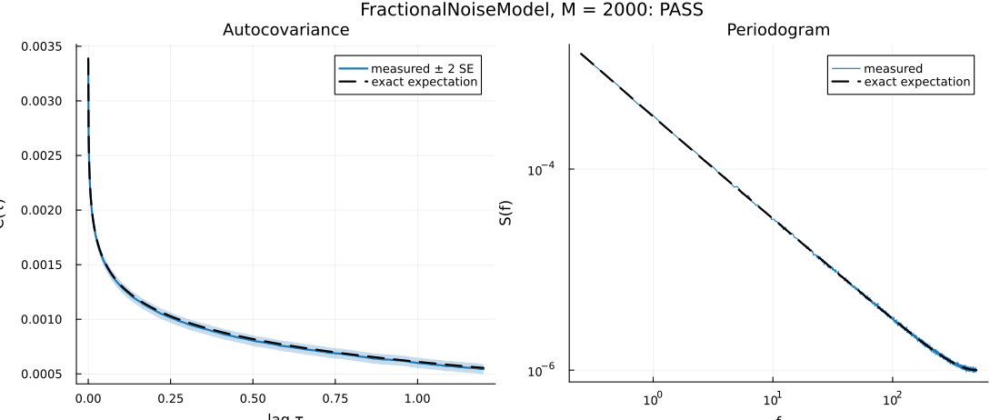

In [32]:
pink = FractionalNoiseModel(1.0, 1e-3)
pink_ens = generate_ensemble(pink, (0.0, 4.0), 1e-3, M_NOISE; rng=Xoshiro(SEED + 1))
pink_rep = validate_noise_model(pink, pink_ens)
display(pink_rep)
save!(plot_validation(pink_rep), "noise_pink_validation")

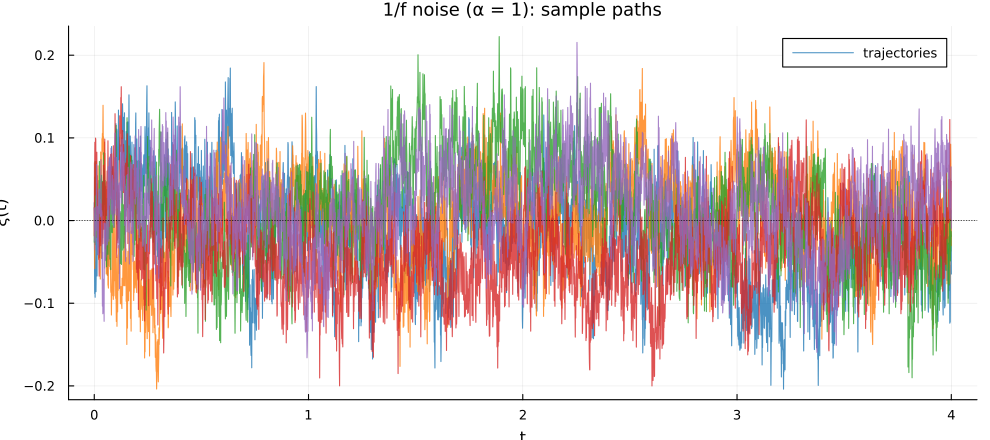

In [33]:
save!(plot_noise_traces(pink_ens; n_show=5, title="1/f noise (α = 1): sample paths"), "noise_pink_traces")

**Nonstationary variance.** The measured Var ξ(t) across trajectories is compared with the exact
Var[x_n] = Q_d Σ_{k≤n} h_k², where h is the filter's pulse response. The band is ± 2 SE of a sample
variance, Var·√(2/(M−1)).

largest |z| of Var ξ(t) over all 4001 times: 4.10  (pointwise; correlated across t)


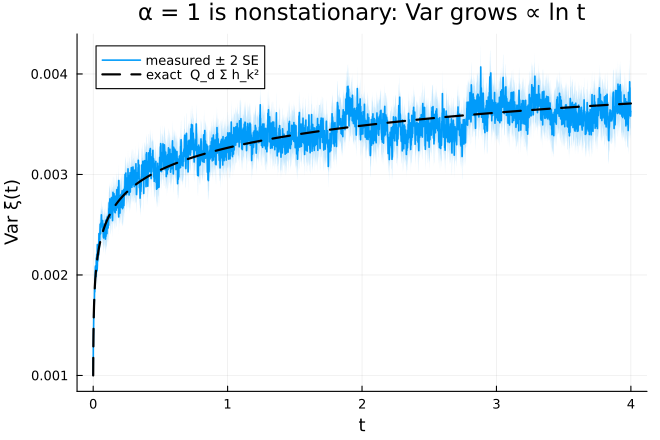

In [34]:
t_p    = times(pink_ens)
v_meas = vec(var(samples(pink_ens); dims=2))
v_exp  = expected_variance(pink, ntimes(pink_ens), timestep(pink_ens))
se_v   = v_exp .* sqrt(2 / (M_NOISE - 1))
z_v    = maximum(abs.(v_meas .- v_exp) ./ se_v)
@printf("largest |z| of Var ξ(t) over all %d times: %.2f  (pointwise; correlated across t)\n", length(t_p), z_v)
p = plot(t_p, v_meas; ribbon=2 .* se_v, fillalpha=0.25, lw=1.5, label="measured ± 2 SE",
         xlabel="t", ylabel="Var ξ(t)", title="α = 1 is nonstationary: Var grows ∝ ln t")
plot!(p, t_p, v_exp; lw=2, ls=:dash, color=:black, label="exact  Q_d Σ h_k²")
save!(p, "noise_pink_variance")

**Other exponents.** For each α, the spectral slope β̂ fitted to the measured periodogram is
compared with **the same fit applied to the exact expected periodogram**, not with α itself.
The finite record bends the spectrum slightly, so the fit's target is not exactly α.

In [35]:
@printf("%5s   %-18s %-14s %s\n", "α", "β̂ (measured)", "β (exact E[S])", "report")
for (k, α) in enumerate((0.5, 1.0, 1.5))
    m = FractionalNoiseModel(α, 1e-3)
    e = generate_ensemble(m, (0.0, 4.0), 1e-3, max(200, M_NOISE ÷ 4); rng=Xoshiro(SEED + 20 + k))
    r = validate_noise_model(m, e)
    @printf("%5.2f   %.4f ± %.4f    %.4f         %s\n", α, r.slope.β, r.slope.se, r.slope.β_expected,
            passed(r) ? "PASS" : "FAIL")
end

    α   β̂ (measured)       β (exact E[S]) report
 0.50   0.4987 ± 0.0055    0.5005         PASS
 1.00   1.0066 ± 0.0055    1.0058         PASS
 1.50   1.5357 ± 0.0061    1.5332         PASS


## 2. Band-limited 1/f noise (the Mathematica kernel)

S(f) = Q/f between f_l = 1/2π and f_h = 100/2π, and zero outside. Its autocovariance is
C(τ) = Q[Ci(100|τ|) − Ci(|τ|)], the kernel used in Mathematica. It is stationary, because the
cutoffs remove the divergent power at both ends (Dutta & Horn 1981, p. 499).

Noise validation: BandLimitedOneOverFNoiseModel(1.0, 0.15915494309189535, 15.915494309189533, 8)
  2000 trajectories × 1001 points, dt = 0.01
  [PASS] mean at t = T                                |z| = 0.94   (limit 3.29)  x̄ = 0.04533, expected 0.0
  [PASS] variance at t = T                            |z| = 0.17   (limit 3.29)  s² = 4.629, expected 4.605
  [PASS] autocovariance (301 lags, demean = :known)   |z| = 1.79   (limit 4.65)  max |z| over lags
  [PASS] periodogram (500 frequencies)                |z| = 2.88   (limit 4.75)  max |z| over frequencies
  spectral slope: β̂ = 1.0012 ± 0.0056, expected 1.0012
  overall: PASS

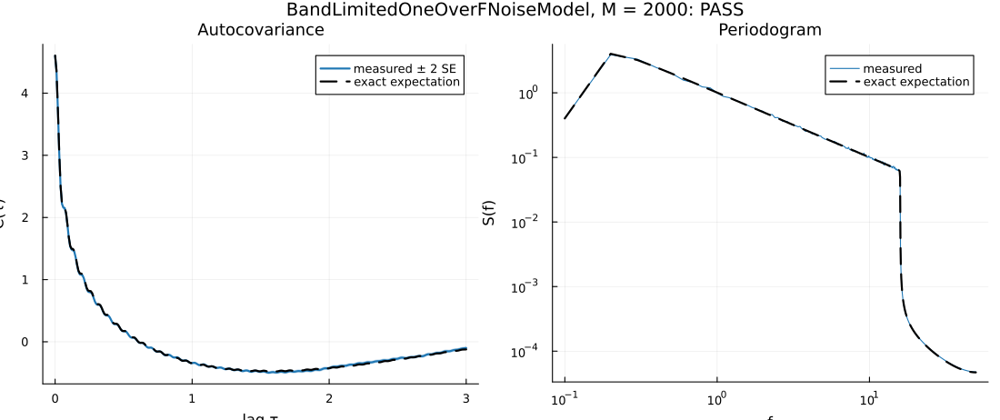

In [36]:
bl = BandLimitedOneOverFNoiseModel(1.0, 1 / (2π), 100 / (2π))
bl_ens = generate_ensemble(bl, (0.0, 10.0), 1e-2, M_NOISE; rng=Xoshiro(SEED + 2))
bl_rep = validate_noise_model(bl, bl_ens)
display(bl_rep)
save!(plot_validation(bl_rep), "noise_bandlimited_validation")

## 3. Ornstein–Uhlenbeck noise: the noise of the thesis (Eq. 3.10)

dξ = −ξ/τ_c dt + √(2σ²/τ_c) dW, started from its stationary distribution. The generator applies the
exact solution over each step (Wikipedia, *Formal solution*):
ξ_{k+1} = e^{−Δt/τ_c} ξ_k + σ√(1 − e^{−2Δt/τ_c}) η_k. So there is **no time-step error**, and the
old "convergence in dt" study is replaced by the exactness check at the end of this section.

Noise validation: OUNoiseModel(0.0, 1.0, 1.0)
  2000 trajectories × 2001 points, dt = 0.01
  [PASS] mean at t = T                                |z| = 1.47   (limit 3.29)  x̄ = -0.03288, expected 0.0
  [PASS] variance at t = T                            |z| = 1.36   (limit 3.29)  s² = 0.9569, expected 1.0
  [PASS] autocovariance (601 lags, demean = :known)   |z| = 1.64   (limit 4.79)  max |z| over lags
  [PASS] periodogram (1000 frequencies)               |z| = 3.63   (limit 4.89)  max |z| over frequencies
  spectral slope: β̂ = 1.9486 ± 0.0079, expected 1.9533
  overall: PASS

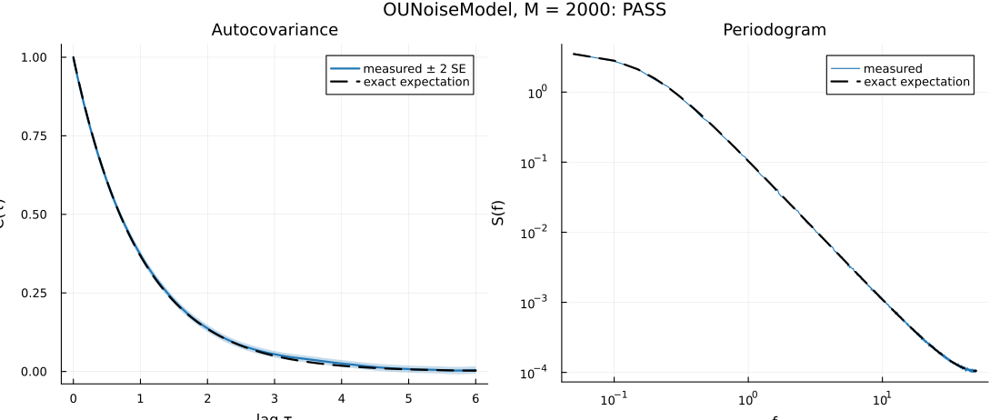

In [37]:
ou = OUNoiseModel(1.0, τc)
ou_ens = generate_ensemble(ou, (0.0, 20.0), 1e-2, M_NOISE; rng=Xoshiro(SEED + 3))
ou_rep = validate_noise_model(ou, ou_ens)
display(ou_rep)
save!(plot_validation(ou_rep), "noise_ou_validation")

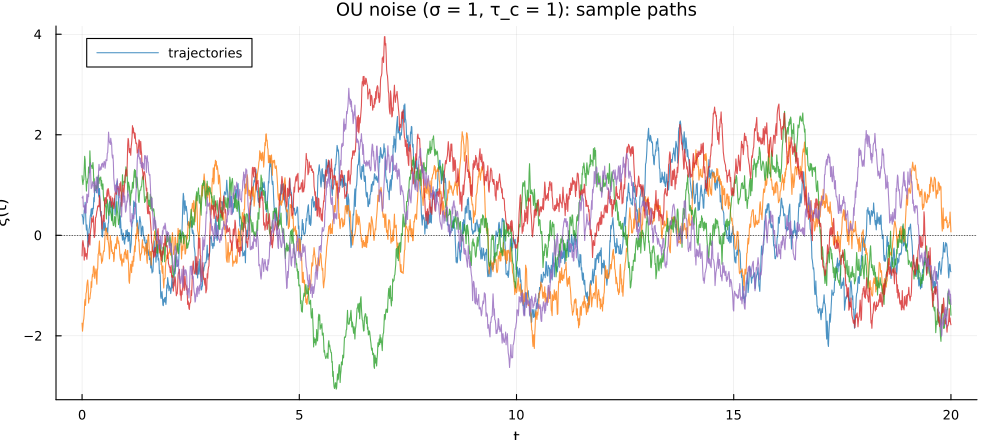

In [38]:
save!(plot_noise_traces(ou_ens; n_show=5, title="OU noise (σ = 1, τ_c = 1): sample paths"), "noise_ou_traces")

**Marginal distribution.** ξ(T) should be Gaussian N(0, σ²). The skewness and excess kurtosis
should both be 0, with standard errors √(6/M) and √(24/M).

skewness        = +0.017 ± 0.055   (Gaussian: 0)
excess kurtosis = -0.066 ± 0.110   (Gaussian: 0)


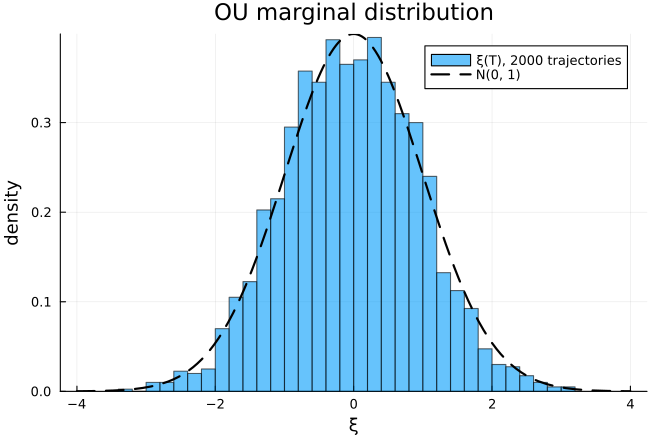

In [39]:
x  = samples(ou_ens)[end, :]
xc = x .- mean(x)
skew = mean(xc .^ 3) / std(x)^3
kurt = mean(xc .^ 4) / std(x)^4 - 3
@printf("skewness        = %+.3f ± %.3f   (Gaussian: 0)\n", skew, sqrt(6 / length(x)))
@printf("excess kurtosis = %+.3f ± %.3f   (Gaussian: 0)\n", kurt, sqrt(24 / length(x)))
p = histogram(x; normalize=:pdf, bins=40, alpha=0.6, label="ξ(T), $(length(x)) trajectories",
              xlabel="ξ", ylabel="density", title="OU marginal distribution")
plot!(p, z -> exp(-z^2 / 2) / sqrt(2π), -4, 4; lw=2, ls=:dash, color=:black, label="N(0, 1)")
save!(p, "noise_ou_marginal")

**Correlation time.** An exponential fit to the measured autocovariance should return τ_c = 1.
(The ± is the regression SE, which is optimistic because neighbouring lags are correlated. The
rigorous test is the autocovariance check in the report above.)

In [40]:
a_ou = autocovariance(ou_ens; max_lag=500)
fit  = exponential_fit(a_ou.lags, a_ou.C)
@printf("τ̂_c = %.4f ± %.4f  (true %.1f), fitted over %d lags\n", fit.τ_c, fit.se, τc, fit.n)

τ̂_c = 1.0230 ± 0.0012  (true 1.0), fitted over 313 lags


**Exact at any time step.** The same model is validated at very different Δt. All should pass,
including Δt = τ_c/2, where an Euler–Maruyama integrator would be visibly wrong.

In [41]:
for (k, dt) in enumerate((0.5, 0.1, 0.01))
    e = generate_ensemble(ou, (0.0, 1000dt), dt, M_NOISE; rng=Xoshiro(SEED + 30 + k))
    r = validate_noise_model(ou, e)
    @printf("Δt = %-5g  %s   max |z| = %.2f\n", dt, passed(r) ? "PASS" : "FAIL",
            maximum(c.statistic for c in r.checks))
end

Δt = 0.5    PASS   max |z| = 3.32
Δt = 0.1    PASS   max |z| = 3.54
Δt = 0.01   PASS   max |z| = 3.41


## 4. White noise

White noise is the simplest case, and a sanity check of the whole validation pipeline.

In [42]:
wn = WhiteNoiseModel(1.0)
wn_rep = validate_noise_model(wn, generate_ensemble(wn, (0.0, 10.0), 1e-2, M_NOISE; rng=Xoshiro(SEED + 4)))
display(wn_rep)

Noise validation: WhiteNoiseModel(0.0, 1.0)
  2000 trajectories × 1001 points, dt = 0.01
  [PASS] mean at t = T                                |z| = 0.16   (limit 3.29)  x̄ = -0.00349, expected 0.0
  [PASS] variance at t = T                            |z| = 0.11   (limit 3.29)  s² = 0.9964, expected 1.0
  [PASS] autocovariance (301 lags, demean = :known)   |z| = 2.91   (limit 4.65)  max |z| over lags
  [PASS] periodogram (500 frequencies)                |z| = 4.12   (limit 4.75)  max |z| over frequencies
  spectral slope: β̂ = 0.0002 ± 0.0036, expected -0.0
  overall: PASS

## 5. Part I summary

In [43]:
noise_reports = ["1/f, α = 1" => pink_rep, "band-limited 1/f" => bl_rep, "OU (thesis noise)" => ou_rep,
                 "white" => wn_rep]
println(rpad("model", 20), rpad("result", 8), "  |z| / limit for: mean, variance, autocovariance, periodogram")
for (name, r) in noise_reports
    println(rpad(name, 20), rpad(passed(r) ? "PASS" : "FAIL", 8), "  ",
            join([@sprintf("%.2f/%.2f", c.statistic, c.threshold) for c in r.checks], "   "))
end

model               result    |z| / limit for: mean, variance, autocovariance, periodogram
1/f, α = 1          PASS      0.80/3.29   0.67/3.29   0.66/4.93   3.82/5.03
band-limited 1/f    PASS      0.94/3.29   0.17/3.29   1.79/4.65   2.88/4.75
OU (thesis noise)   PASS      1.47/3.29   1.36/3.29   1.64/4.79   3.63/4.89
white               PASS      0.16/3.29   0.11/3.29   2.91/4.65   4.12/4.75


# Part II: brute-force reference for the thesis master equations

**What is computed.** For each noise trajectory ξ(t), the solver integrates the von Neumann
equation dρ/dt = −i[H(t), ρ] with the H of Eq. 3.12, and then averages over trajectories.
The average ⟨ρ(t)⟩ is exactly what the SMNE (Eq. 2.57) and the PLME (Eq. 1.37) approximate.
The brute-force result has only two errors, and both are measured below:

* **statistical**, from the finite number of trajectories: reported as an SE on every number;
* **time step**: checked in §8.

Between noise samples, ξ is linearly interpolated.

## 6. The model is Eq. 3.12, solved two independent ways

In [44]:
g1 = CosineGate(θ, 1.0)
println("H(t = 0.3, ξ = 0.7) = f_x/2·σx + ξ/2·σz:")
display(hamiltonian(g1, 0.7, 0.3))
@printf("‖U_Ideal − (1 − iσx)/√2‖ = %.1e   (Eq. 3.8)\n", maximum(abs, ideal_gate(g1) - (I2 - im * σx) / sqrt(2)))
@printf("θ(t_g) = %.12f  (= π/2)\n", rotation_angle(g1, g1.tg))

H(t = 0.3, ξ = 0.7) = f_x/2·σx + ξ/2·σz:


2×2 Matrix{ComplexF64}:
   0.35+0.0im  1.0281+0.0im
 1.0281+0.0im   -0.35+0.0im

‖U_Ideal − (1 − iσx)/√2‖ = 1.1e-16   (Eq. 3.8)
θ(t_g) = 1.570796326795  (= π/2)


**Two independent solvers.** `:rk4` integrates dS/dt = −i(1⊗H − Hᵀ⊗1)S exactly as written, using
nothing but `hamiltonian`. `:magnus` works in the interaction picture with exact SU(2) steps. On one
strong, rough trajectory (σ = 3) they must agree, and each must be 4th order: the error falls 16×
when the step halves.

In [45]:
e_one = generate_ensemble(OUNoiseModel(3.0, τc), (0.0, 1.0), 1 / NSTEPS, 1; rng=Xoshiro(SEED + 10))
t_one, ξ_one = times(e_one), e_one[1]
S_mag = propagate_trajectory(g1, t_one, ξ_one; solver=:magnus, substeps=8)[end]
S_rk4 = propagate_trajectory(g1, t_one, ξ_one; solver=:rk4,    substeps=8)[end]
@printf("max |S_magnus − S_rk4| = %.2e\n\n", maximum(abs, S_mag - S_rk4))
S_ref = propagate_trajectory(g1, t_one, ξ_one; substeps=64)[end]
for solver in (:magnus, :rk4)
    err = [maximum(abs, propagate_trajectory(g1, t_one, ξ_one; solver, substeps=s)[end] - S_ref) for s in (1, 2, 4)]
    @printf("%-7s errors %.2e  %.2e  %.2e   observed order %.2f, %.2f\n", solver, err[1], err[2], err[3],
            log2(err[1] / err[2]), log2(err[2] / err[3]))
end

max |S_magnus − S_rk4| = 3.81e-13

magnus  errors 6.31e-10  3.94e-11  2.45e-12   observed order 4.00, 4.00
rk4     errors 9.42e-10  5.79e-11  3.60e-12   observed order 4.02, 4.01


## 7. An exact result the brute force must reproduce

With the drive off (θ = 0), every H(t) commutes, and for Gaussian noise the coherence is known exactly:

$$\langle\rho_{01}(t)\rangle = \tfrac12\exp\!\Bigl[-\sigma^2\tau_c\bigl(t - \tau_c(1-e^{-t/\tau_c})\bigr)\Bigr].$$

In this case the 2nd-order master equation is also exact, so both methods must reproduce it.

In [46]:
g0, σ0 = CosineGate(0.0, 1.0), 1.0
r0 = simulate_gate(g0, OUNoiseModel(σ0, τc), M_GATE; dt=1 / NSTEPS, rng=Xoshiro(SEED + 11),
                   save_every=NSTEPS)
fs0   = final_state(r0, cardinal_states().xp)
exact = exp(-σ0^2 * τc * (1 - τc * (1 - exp(-1 / τc)))) / 2
me0   = apply_channel(tcl2_evolution(g0, OUNoiseModel(σ0, τc)).S[end], cardinal_states().xp)[1, 2]
@printf("exact                 ρ₀₁ = %.6f\n", exact)
@printf("brute force           ρ₀₁ = %.6f ± %.6f   z = %+.2f\n", real(fs0.ρ[1, 2]), real(fs0.se[1, 2]),
        (real(fs0.ρ[1, 2]) - exact) / real(fs0.se[1, 2]))
@printf("2nd-order master eq.  ρ₀₁ = %.6f   relative error %.1e\n", real(me0), abs(real(me0) / exact - 1))

exact                 ρ₀₁ = 0.346100
brute force           ρ₀₁ = 0.347414 ± 0.001816   z = +0.72
2nd-order master eq.  ρ₀₁ = 0.346100   relative error 1.9e-09


## 8. One operating point in detail, and the time-step check

This section uses t_g = τ_c and δ = 0.1. First, the **noise that drives the qubit is itself
validated**. Then both solvers run on exactly those trajectories.

In [47]:
σ1  = sigma_for_delta(0.1, τc, θ, 1.0)
m1  = OUNoiseModel(σ1, τc)
@printf("δ = %.3f  ⇒  σ = %.4f\n", small_noise_parameter(g1, m1), σ1)
ens1 = generate_ensemble(m1, (0.0, 1.0), 1 / NSTEPS, M_GATE; rng=Xoshiro(SEED + 12))
display(validate_noise_model(m1, ens1))

δ = 0.100  ⇒  σ = 0.4315


Noise validation: OUNoiseModel(0.0, 0.4315200909712764, 1.0)
  10000 trajectories × 401 points, dt = 0.0025
  [PASS] mean at t = T                                |z| = 0.38   (limit 3.29)  x̄ = 0.001644, expected 0.0
  [PASS] variance at t = T                            |z| = 1.37   (limit 3.29)  s² = 0.1826, expected 0.1862
  [PASS] autocovariance (121 lags, demean = :known)   |z| = 0.85   (limit 4.46)  max |z| over lags
  [PASS] periodogram (200 frequencies)                |z| = 2.38   (limit 4.56)  max |z| over frequencies
  spectral slope: β̂ = 1.9864 ± 0.003, expected 1.9857
  overall: PASS

In [48]:
t_mag = @elapsed r_mag = simulate_gate(g1, ens1; save_every=4)
t_rk4 = @elapsed r_rk4 = simulate_gate(g1, ens1; solver=:rk4, substeps=2, save_every=4)
e_mag, e_rk4 = average_error(r_mag), average_error(r_rk4)
@printf("⟨ε⟩ Magnus = %.6f ± %.6f   (%.1f s)\n", e_mag.ε, e_mag.se, t_mag)
@printf("⟨ε⟩ RK4    = %.6f ± %.6f   (%.1f s)\n", e_rk4.ε, e_rk4.se, t_rk4)
@printf("difference = %.1e  (same trajectories, so this is solver error only; compare with the SE)\n",
        e_mag.ε - e_rk4.ε)
@printf("F̄ from Eq. 3.24 = %.8f,  from the trace formula = %.8f\n",
        fidelity_map(final_channel(r_mag), ideal_gate(g1)), fidelity_trace_formula(final_channel(r_mag), ideal_gate(g1)))
@printf("averaged map is CPTP: %s\n", is_cptp(final_channel(r_mag)))

⟨ε⟩ Magnus = 0.016532 ± 0.000212   (1.9 s)
⟨ε⟩ RK4    = 0.016532 ± 0.000212   (16.8 s)
difference = 6.5e-14  (same trajectories, so this is solver error only; compare with the SE)
F̄ from Eq. 3.24 = 0.98346848,  from the trace formula = 0.98346848
averaged map is CPTP: true


**The six final states** (Eq. 3.21). The exact dynamics must give a valid density matrix with real
eigenvalues in [0, 1] for every state.

     λ₁ ± SE                 λ₂ ± SE                 max|Im λ|  valid ρ
zp   0.987611 ± 0.000143    0.012389 ± 0.000143    0e+00      true
zm   0.987611 ± 0.000143    0.012389 ± 0.000143    0e+00      true
xp   0.975436 ± 0.000279    0.024564 ± 0.000279    0e+00      true
xm   0.975436 ± 0.000279    0.024564 ± 0.000279    0e+00      true
yp   0.987698 ± 0.000167    0.012302 ± 0.000167    0e+00      true
ym   0.987698 ± 0.000167    0.012302 ± 0.000167    0e+00      true


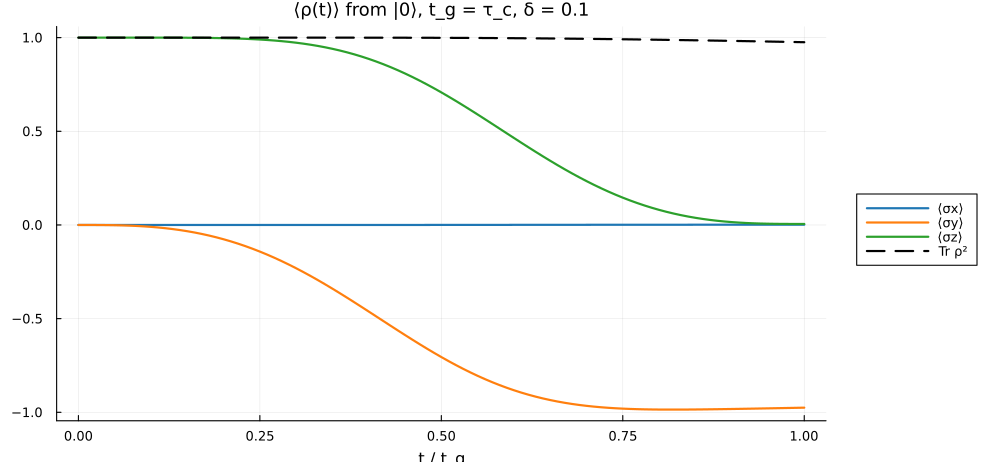

In [49]:
@printf("%-3s  %-22s  %-22s  %-10s %s\n", "", "λ₁ ± SE", "λ₂ ± SE", "max|Im λ|", "valid ρ")
for (name, ρ0) in pairs(cardinal_states())
    ev = final_state_eigenvalues(r_mag, ρ0)
    fs = final_state(r_mag, ρ0)
    @printf("%-3s  %.6f ± %.6f    %.6f ± %.6f    %.0e      %s\n", name, real(ev.λ[1]), ev.se[1],
            real(ev.λ[2]), ev.se[2], maximum(abs.(imag.(ev.λ))), validate_density_matrix(fs.ρ).valid)
end
save!(plot_state_evolution(r_mag, cardinal_states().zp; title="⟨ρ(t)⟩ from |0⟩, t_g = τ_c, δ = 0.1"),
      "gate_state_evolution")

**Is the time step small enough?** For each t_g, at the largest δ, the gate is solved on the *same*
trajectories sampled every 1, 2, 4, 8 and 16 fine steps. Δε is the change relative to the finest grid.
Because the trajectories are identical, Δε is pure time-step error, measured far more precisely than
the Monte-Carlo SE of ε. The production step is t_g/400, which is factor 8 here, and its |Δε| should
sit far inside the grey ± 1 SE band.

t_g = 1.0 τ_c, δ = 0.5:
   dt = t_g/3200   ε = 6.8201e-02 ± 2.4e-03   Δε = +0.00e+00 ± 0.0e+00
   dt = t_g/1600   ε = 6.8201e-02 ± 2.4e-03   Δε = -9.50e-08 ± 1.0e-06
   dt = t_g/800    ε = 6.8201e-02 ± 2.4e-03   Δε = -3.98e-07 ± 2.1e-06
   dt = t_g/400    ε = 6.8196e-02 ± 2.4e-03   Δε = -4.53e-06 ± 4.7e-06
   dt = t_g/200    ε = 6.8196e-02 ± 2.4e-03   Δε = -5.06e-06 ± 9.5e-06
t_g = 0.1 τ_c, δ = 0.06:
   dt = t_g/3200   ε = 1.0505e-03 ± 4.8e-05   Δε = +0.00e+00 ± 0.0e+00
   dt = t_g/1600   ε = 1.0505e-03 ± 4.8e-05   Δε = +4.17e-09 ± 4.7e-09
   dt = t_g/800    ε = 1.0505e-03 ± 4.8e-05   Δε = +5.54e-09 ± 1.0e-08
   dt = t_g/400    ε = 1.0505e-03 ± 4.8e-05   Δε = -9.06e-10 ± 2.1e-08
   dt = t_g/200    ε = 1.0505e-03 ± 4.8e-05   Δε = -2.23e-08 ± 4.5e-08
t_g = 0.01 τ_c, δ = 0.006:
   dt = t_g/3200   ε = 1.0532e-05 ± 4.6e-07   Δε = +0.00e+00 ± 0.0e+00
   dt = t_g/1600   ε = 1.0532e-05 ± 4.6e-07   Δε = +1.70e-11 ± 1.5e-11
   dt = t_g/800    ε = 1.0532e-05 ± 4.6e-07   Δε = +2.71e-11 ± 3.3e-11
 

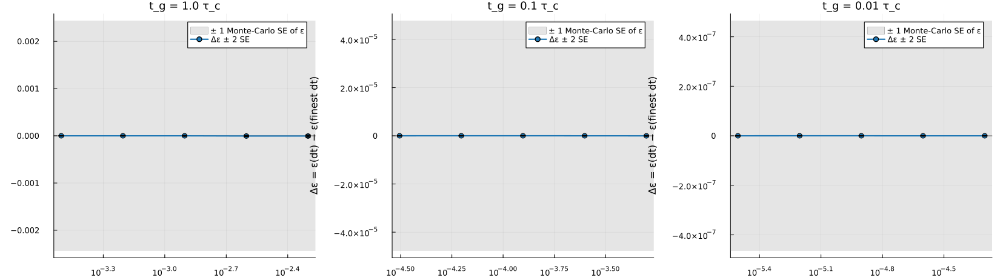

In [50]:
conv_plots = []
for (k, tg) in enumerate(TG)
    g  = CosineGate(θ, tg)
    m  = OUNoiseModel(sigma_for_delta(last(DELTAS[tg]), τc, θ, tg), τc)
    ef = generate_ensemble(m, (0.0, tg), tg / 3200, FAST ? 200 : 1_000; rng=Xoshiro(SEED + 40 + k))
    conv = timestep_convergence(g, ef; factors=(1, 2, 4, 8, 16))
    println("t_g = $tg τ_c, δ = $(last(DELTAS[tg])):")
    for c in conv
        @printf("   dt = t_g/%-5d  ε = %.4e ± %.1e   Δε = %+.2e ± %.1e\n", round(Int, tg / c.dt), c.ε, c.ε_se, c.Δε, c.Δε_se)
    end
    push!(conv_plots, plot_timestep_convergence(conv))
    title!(conv_plots[end], "t_g = $tg τ_c")
end
save!(plot(conv_plots...; layout=(1, 3), size=(1500, 420)), "gate_timestep_convergence")

## 9. δ sweeps: the brute-force reference for Figs. 3.2–3.22

For each t_g, `delta_sweep` varies δ through σ²τ_c (Eq. 3.20), exactly as in the thesis. At each δ
it returns ⟨ε⟩ ± SE and, for every cardinal state, ⟨ρ_j(t_g)⟩ ± SE and λ₁,₂ ± SE.
`tcl2_delta_sweep` solves the 2nd-order master equation (thesis: SMNE(2nd) = PLME(2nd)) at the
same δ values. The noise ensemble behind each sweep is regenerated from its seed and validated first.

*This is the longest cell: a few minutes with `FAST = false`.*

In [51]:
sweeps, me_sweeps = Dict{Float64,Any}(), Dict{Float64,Any}()
for (k, tg) in enumerate(TG)
    g, dt, seed = CosineGate(θ, tg), tg / NSTEPS, SEED + 100k
    # the unit-σ ensemble that delta_sweep generates first, from the same seed: validate it
    unit = generate_ensemble(OUNoiseModel(1.0, τc), (0.0, tg), dt, M_GATE; rng=Xoshiro(seed))
    rep  = validate_noise_model(OUNoiseModel(1.0, τc), unit)
    t_bf = @elapsed sweeps[tg] = delta_sweep(g, τc, DELTAS[tg], M_GATE; dt, rng=Xoshiro(seed))
    t_me = @elapsed me_sweeps[tg] = tcl2_delta_sweep(g, τc, DELTAS[tg])
    @printf("t_g = %-5g noise %s | brute force: %d δ × %d trajectories in %.1f s | 2nd order: %.1f s\n",
            tg, passed(rep) ? "PASS" : "FAIL", length(DELTAS[tg]), M_GATE, t_bf, t_me)
end

t_g = 1     noise PASS | brute force: 10 δ × 10000 trajectories in 18.9 s | 2nd order: 2.2 s
t_g = 0.1   noise PASS | brute force: 12 δ × 10000 trajectories in 22.7 s | 2nd order: 2.5 s
t_g = 0.01  noise PASS | brute force: 12 δ × 10000 trajectories in 22.7 s | 2nd order: 2.5 s


### 9.1 ⟨ε⟩_ξ versus δ (Figs. 3.20–3.22)

The solid line is brute force ± 2 SE; the dashed line is the 2nd-order master equation. The table
gives the relative difference and z = (ε_2nd − ε_bf)/SE. With common random numbers, neighbouring
z values are correlated, so a steady trend across δ is more telling than any single z.

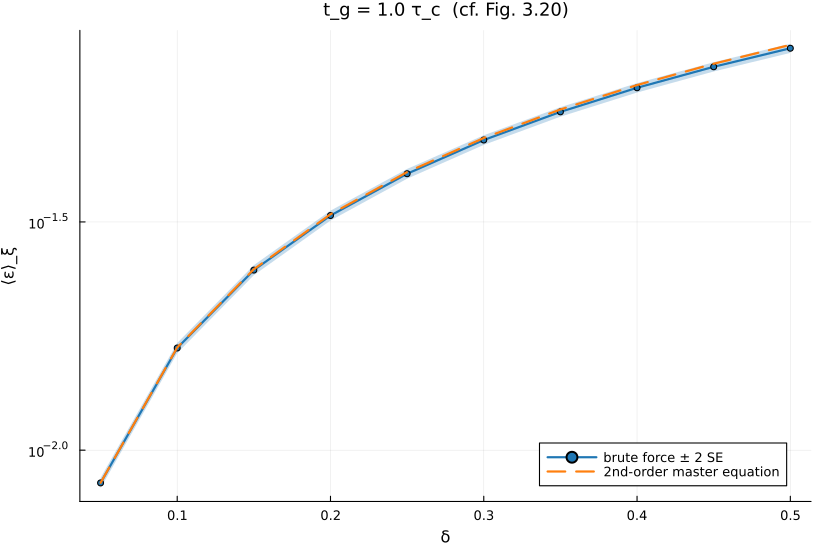

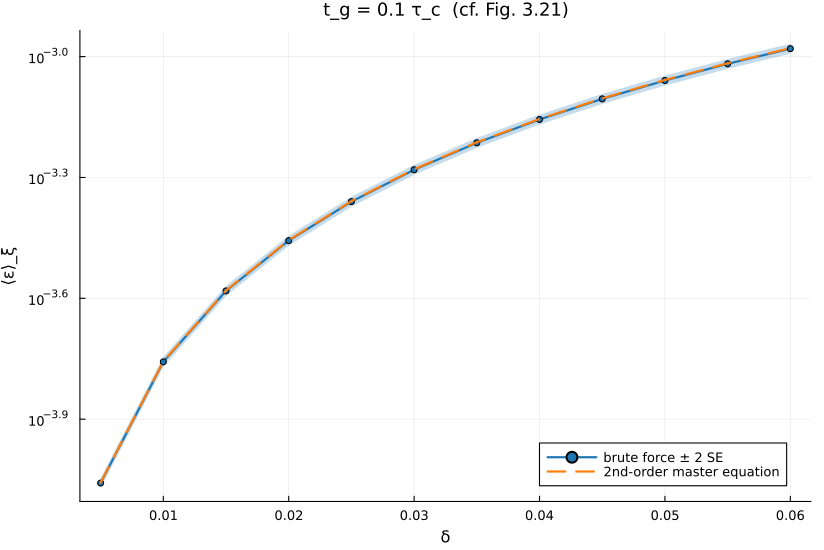

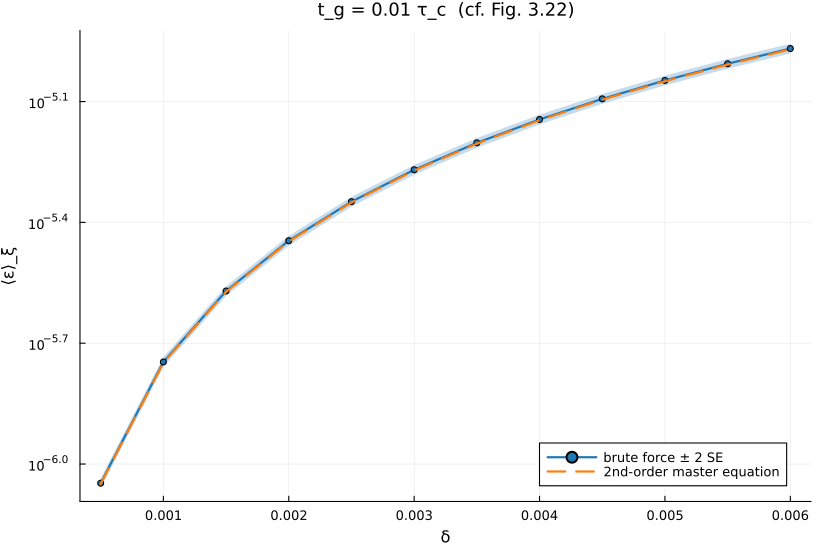

In [52]:
for tg in TG
    p = plot_error_vs_delta(sweeps[tg]; compare="2nd-order master equation" => me_sweeps[tg],
                            title="t_g = $tg τ_c  (cf. Fig. 3.$(FIGNO[tg]))")
    display(save!(p, "error_vs_delta_tg$(tg)"))
end

In [53]:
for tg in TG
    println("t_g = $tg τ_c")
    @printf("   %-8s  %-24s  %-12s  %-10s  %s\n", "δ", "ε brute force ± SE", "ε 2nd order", "rel. diff", "z")
    for (b, m) in zip(sweeps[tg], me_sweeps[tg])
        @printf("   %-8.4f  %.4e ± %.1e      %.4e    %+7.2f%%    %+6.1f\n", b.δ, b.ε, b.ε_se, m.ε,
                100 * (m.ε - b.ε) / b.ε, (m.ε - b.ε) / b.ε_se)
    end
end

t_g = 1.0 τ_c
   δ         ε brute force ± SE        ε 2nd order   rel. diff   z
   0.0500    8.4776e-03 ± 1.1e-04      8.4823e-03      +0.06%      +0.0
   0.1000    1.6743e-02 ± 2.1e-04      1.6786e-02      +0.26%      +0.2
   0.1500    2.4801e-02 ± 3.1e-04      2.4915e-02      +0.46%      +0.4
   0.2000    3.2660e-02 ± 4.1e-04      3.2873e-02      +0.65%      +0.5
   0.2500    4.0324e-02 ± 5.0e-04      4.0664e-02      +0.84%      +0.7
   0.3000    4.7801e-02 ± 5.8e-04      4.8292e-02      +1.03%      +0.8
   0.3500    5.5095e-02 ± 6.6e-04      5.5760e-02      +1.21%      +1.0
   0.4000    6.2211e-02 ± 7.4e-04      6.3072e-02      +1.38%      +1.2
   0.4500    6.9156e-02 ± 8.1e-04      7.0232e-02      +1.56%      +1.3
   0.5000    7.5935e-02 ± 8.8e-04      7.7242e-02      +1.72%      +1.5
t_g = 0.1 τ_c
   δ         ε brute force ± SE        ε 2nd order   rel. diff   z
   0.0050    8.7369e-05 ± 1.2e-06      8.7601e-05      +0.27%      +0.2
   0.0100    1.7471e-04 ± 2.5e-06      1.7518e

### 9.2 Eigenvalues of ⟨ρ_j(t_g)⟩ versus δ (Figs. 3.2–3.19)

These are the thesis's four panels (Re λ₁, Re λ₂, Im λ₁, Im λ₂) for every state and every t_g.
Brute force is exact dynamics, so its Im λ must be zero to rounding and its Re λ must lie in [0, 1].
Any master equation that breaks this is unphysical at that δ.

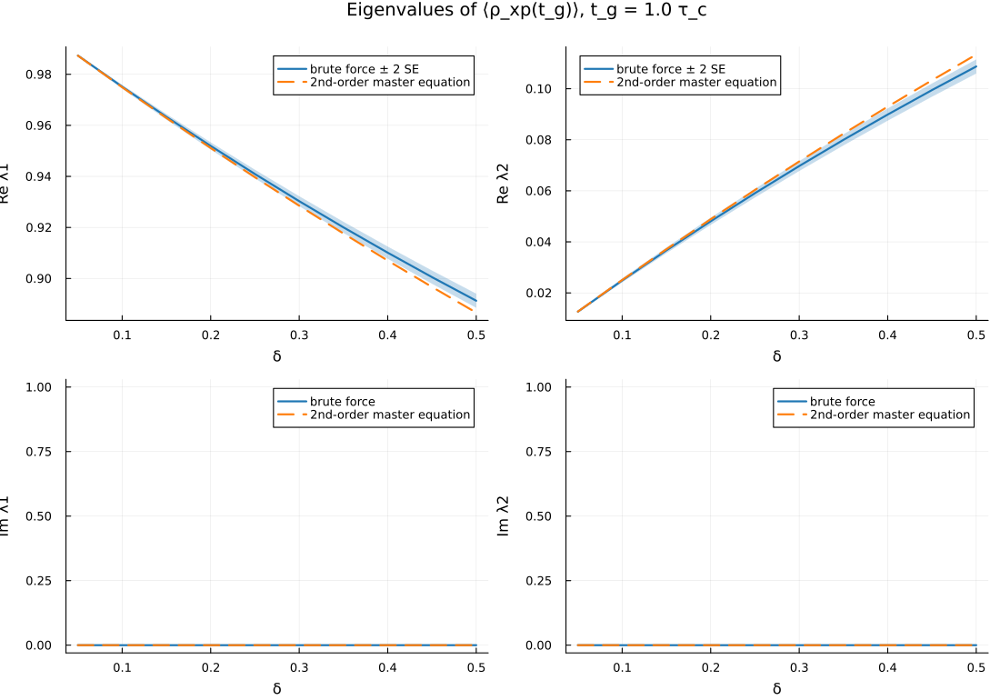

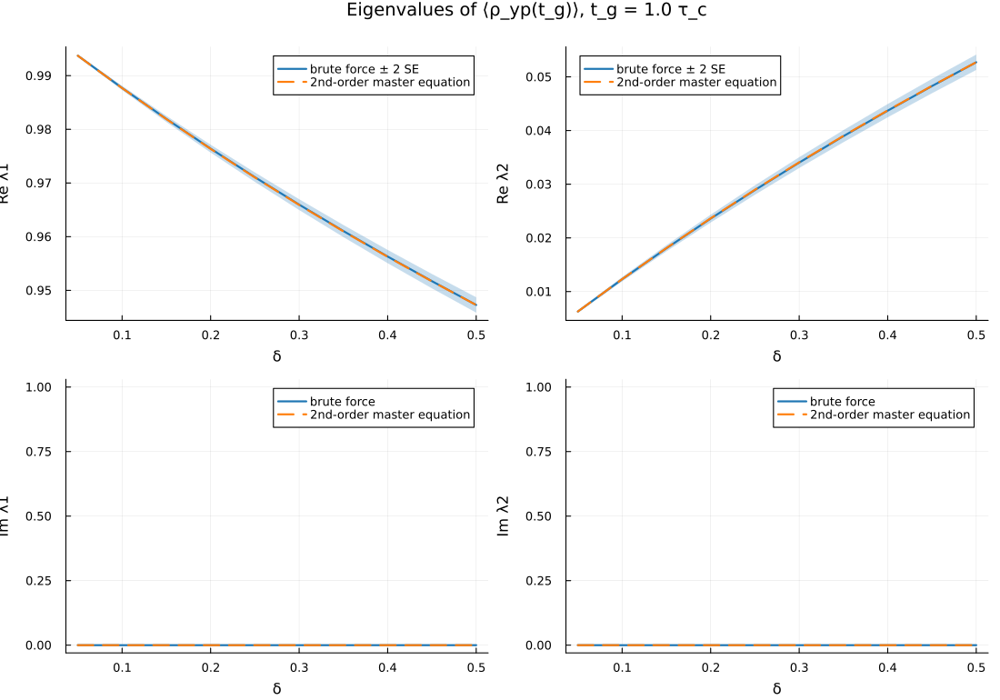

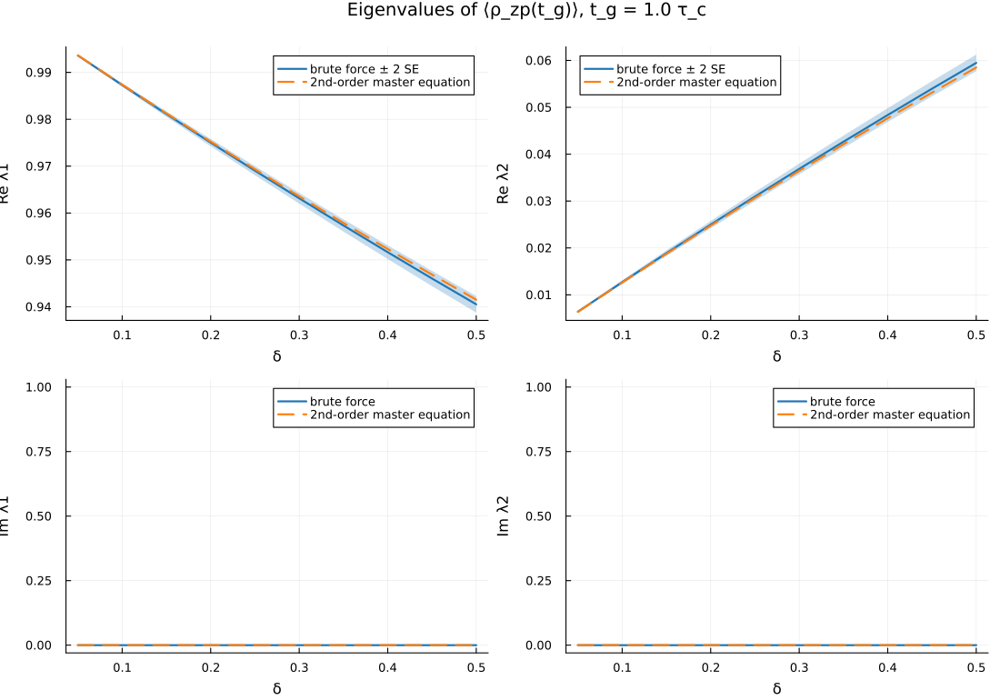

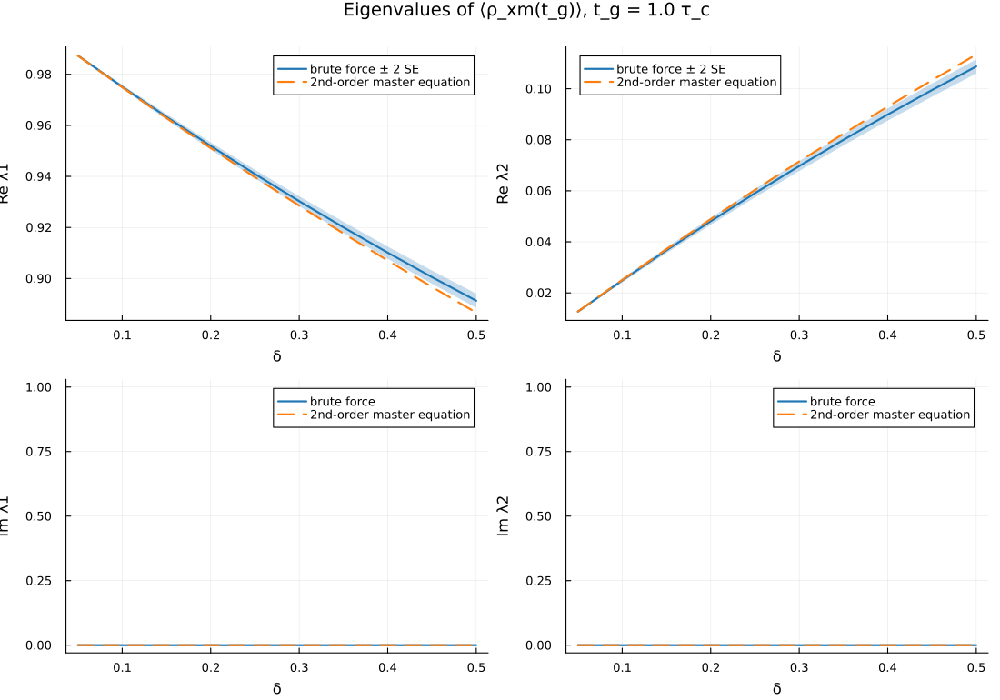

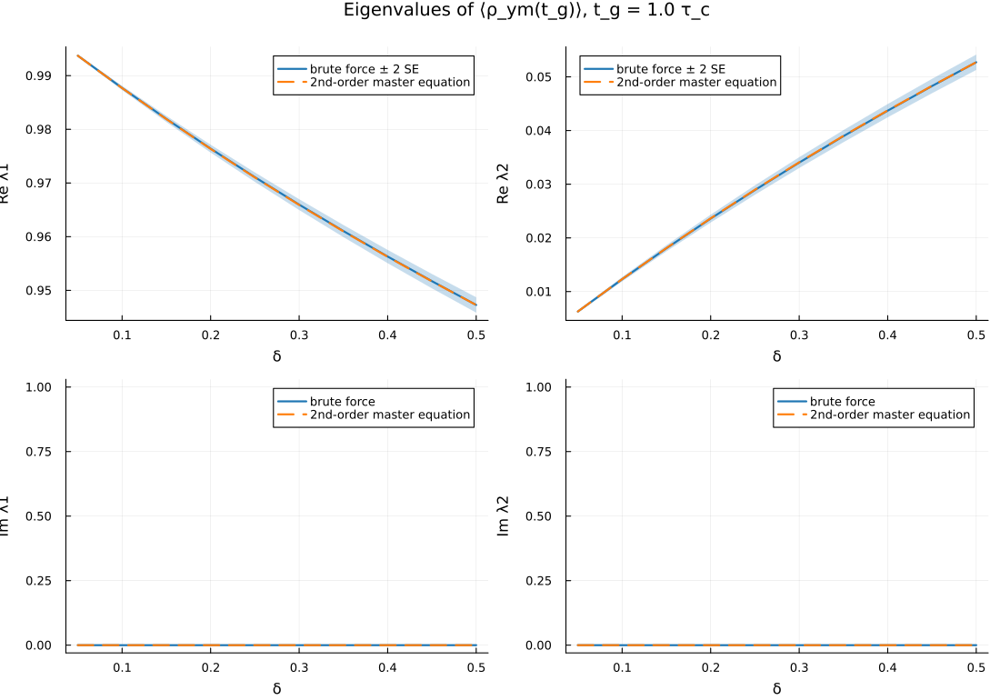

...

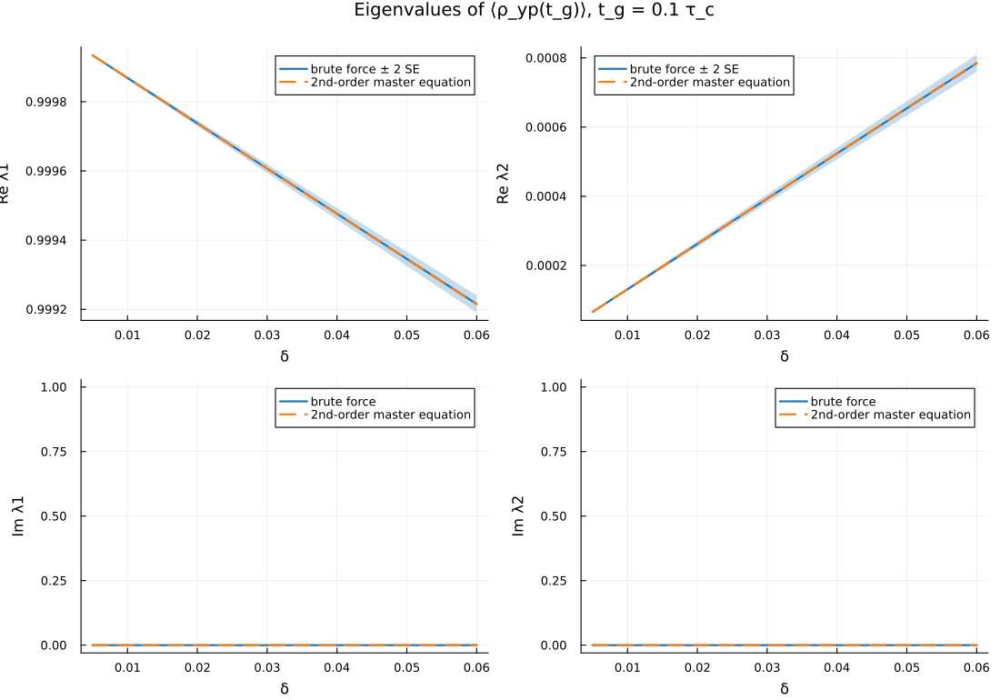

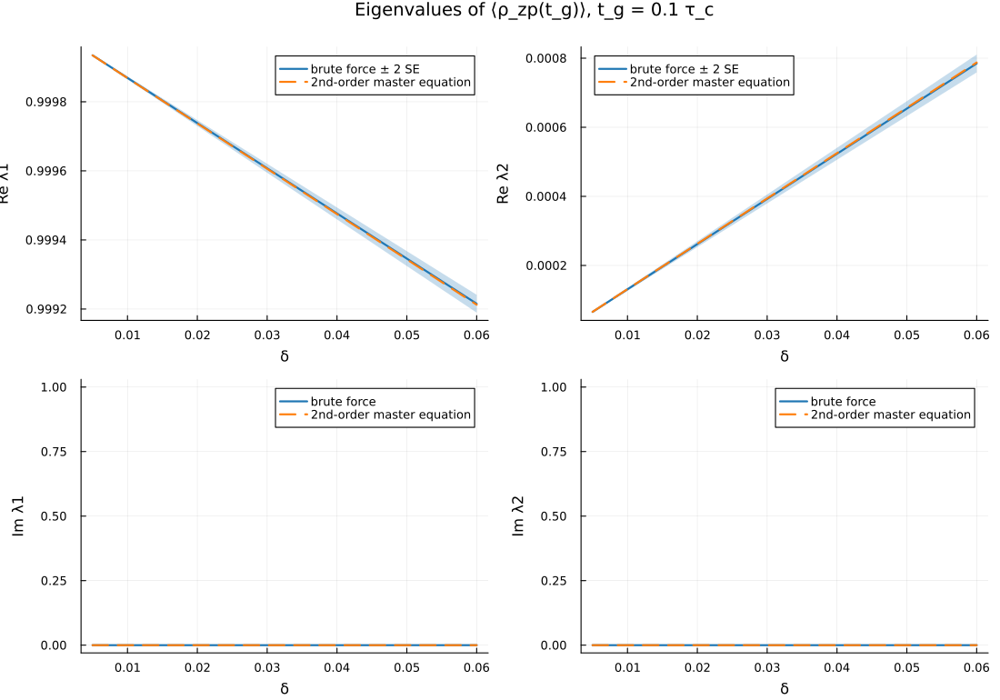

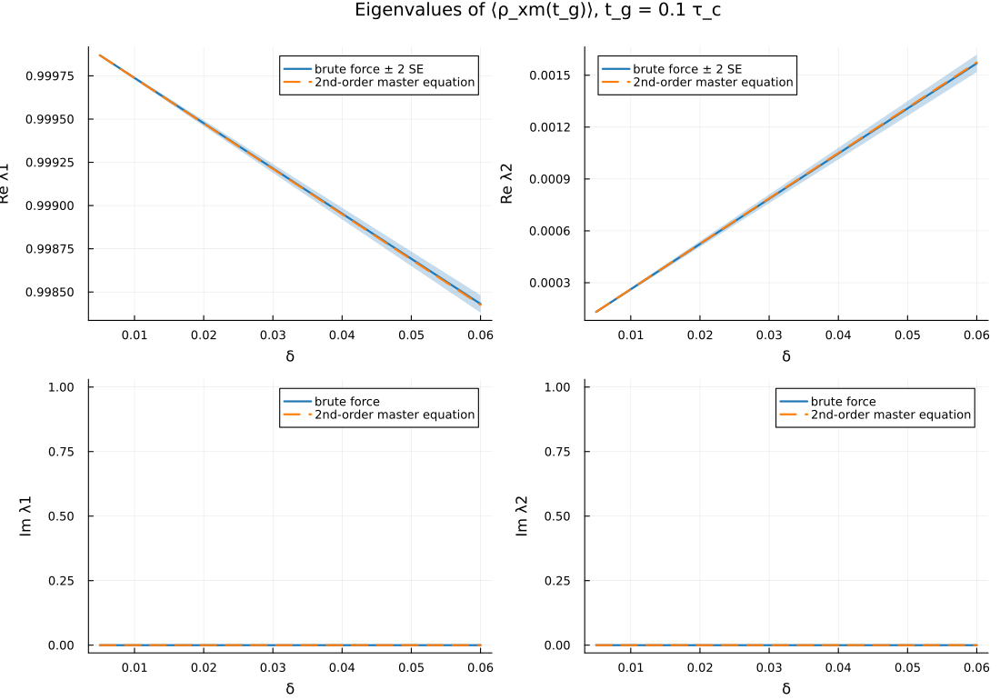

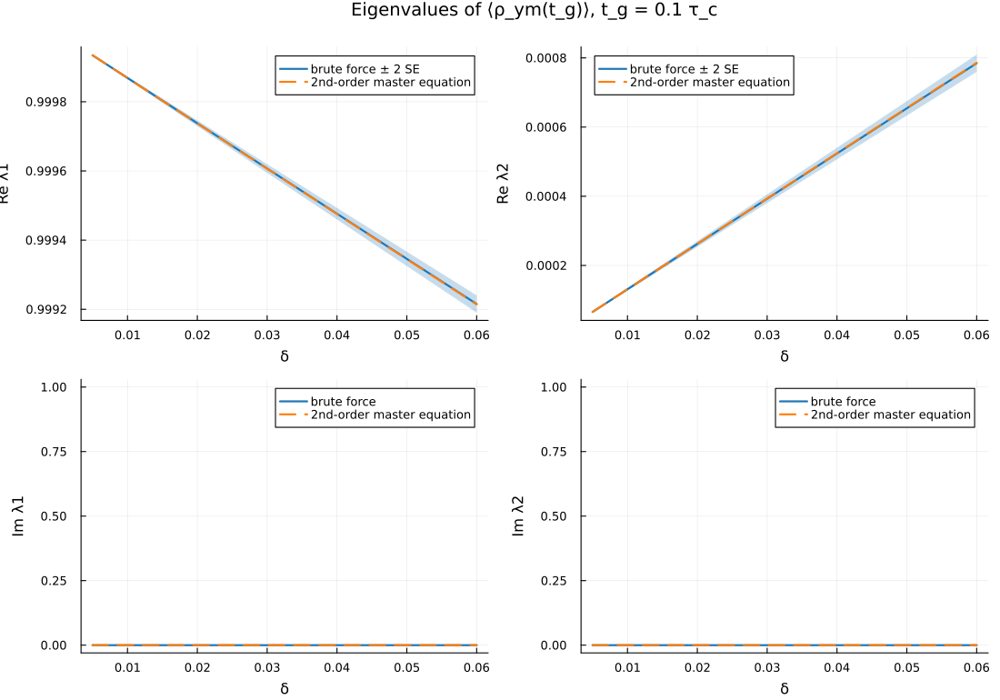

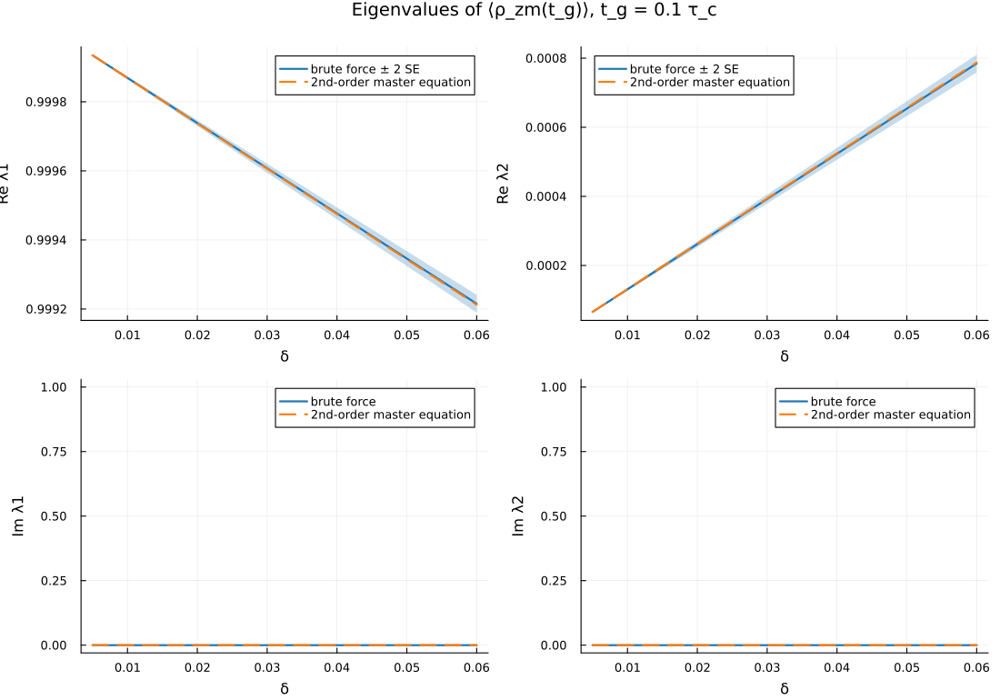

┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194
┌ Warning: No strict

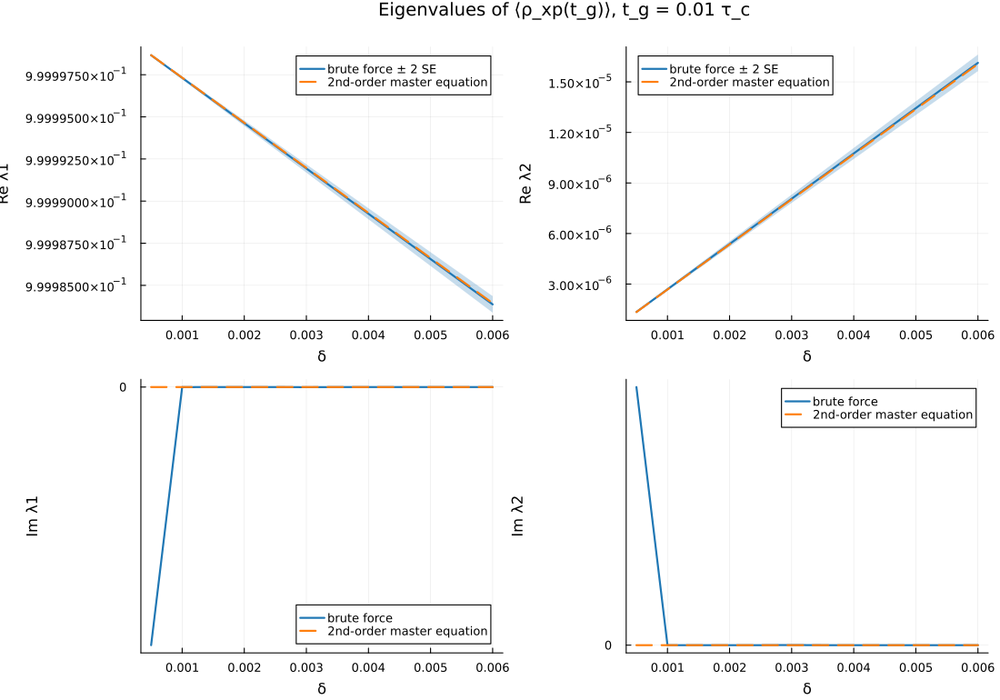

┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194


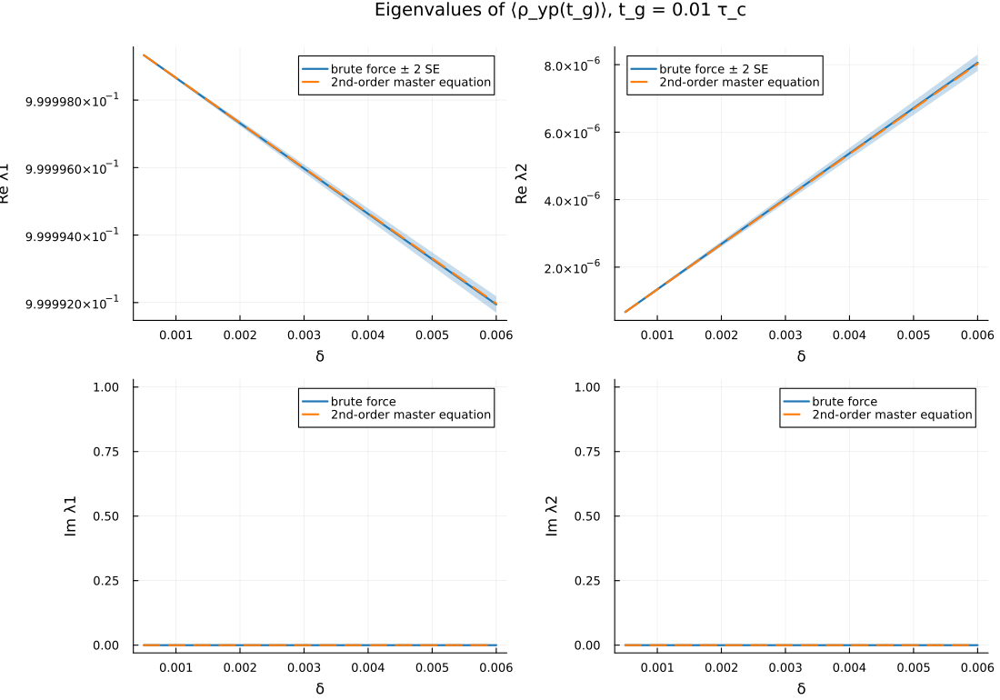

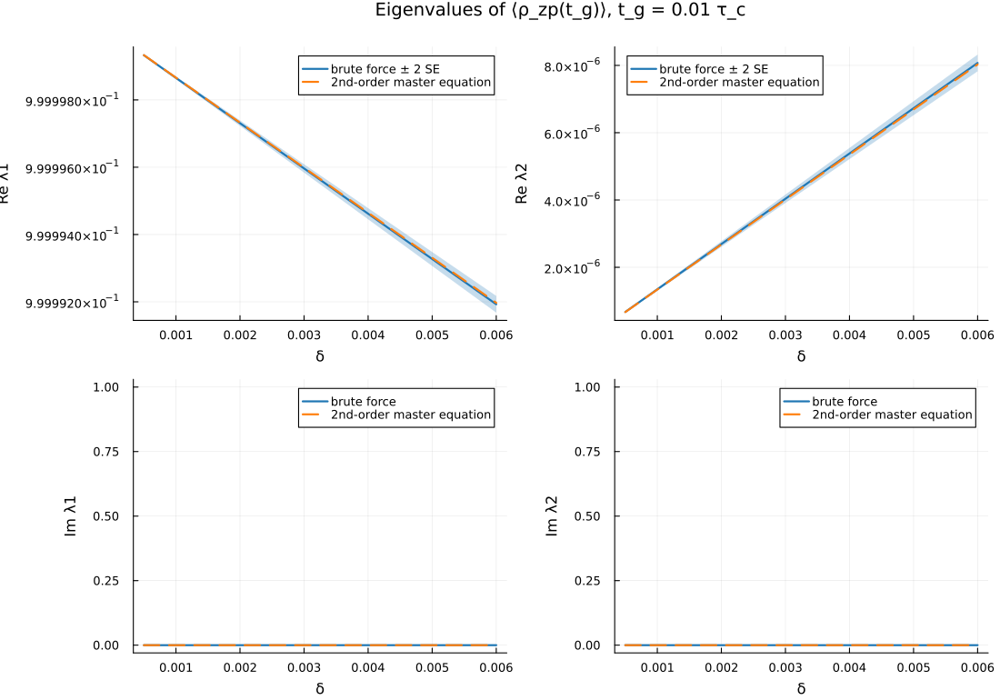

┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194
┌ Warning: No strict

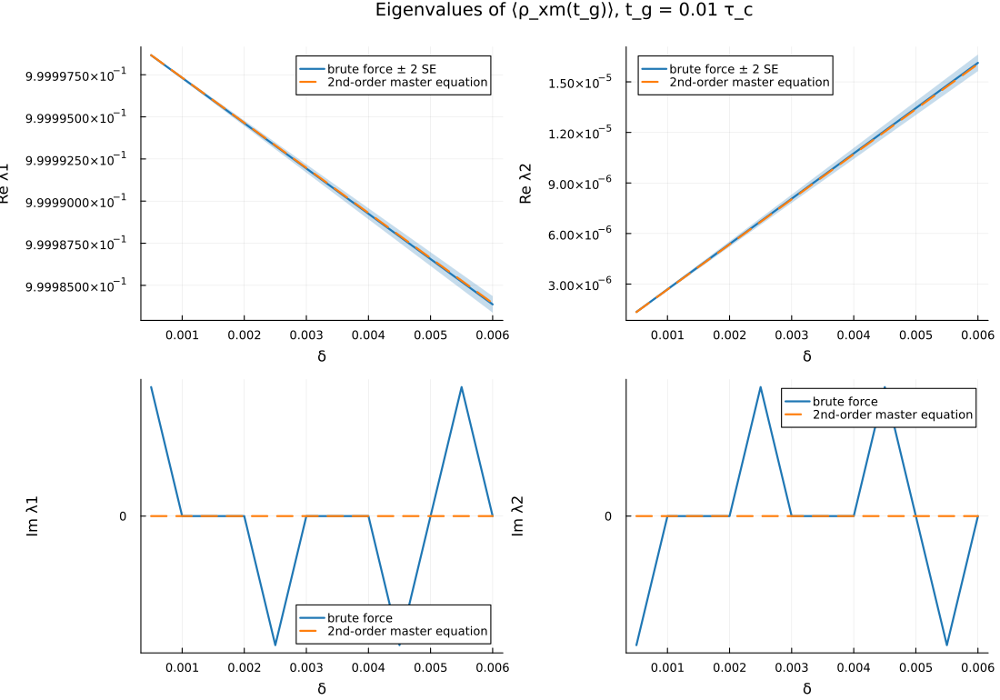

┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194
┌ Warning: No strict ticks found
└ @ PlotUtils ~/.julia/packages/PlotUtils/J9gzB/src/ticks.jl:194


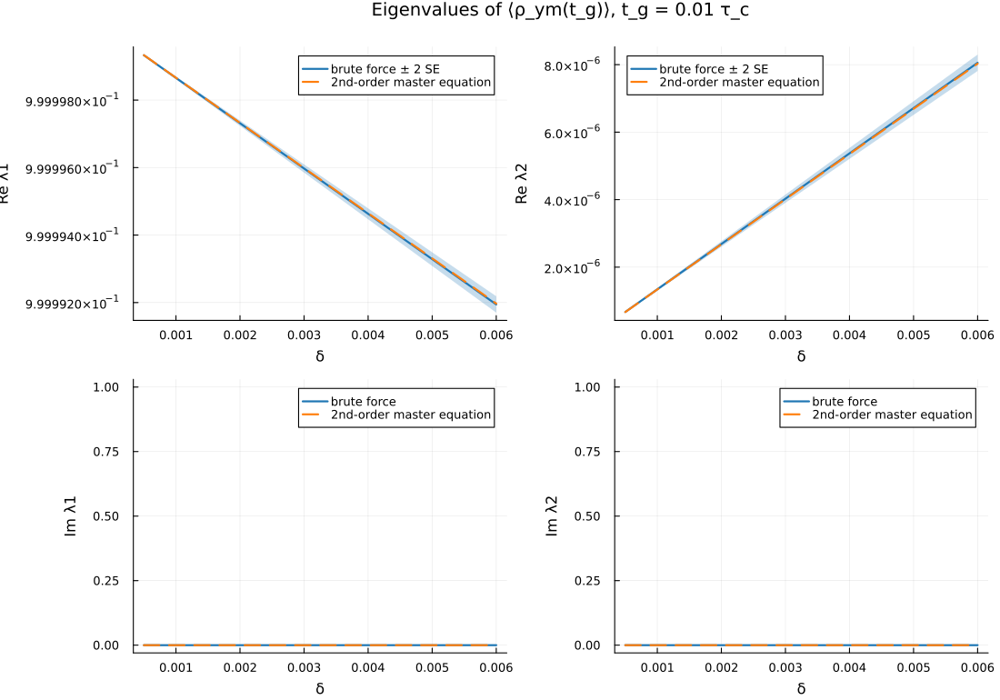

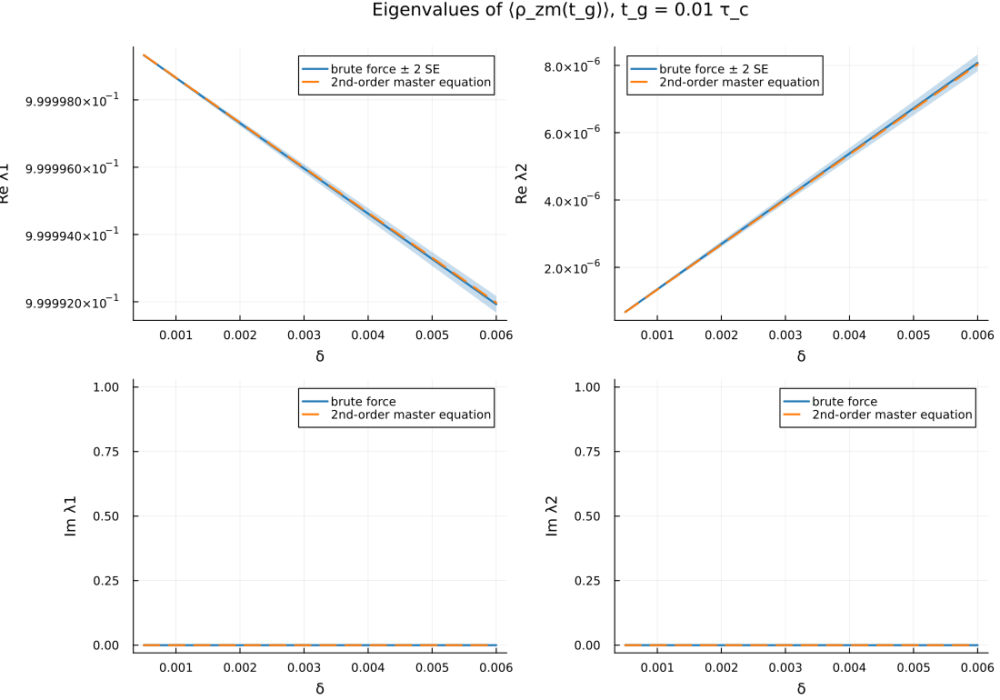

In [54]:
for tg in TG, s in (:xp, :yp, :zp, :xm, :ym, :zm)
    p = plot_eigenvalues_vs_delta(sweeps[tg], s; compare="2nd-order master equation" => me_sweeps[tg],
                                  title="Eigenvalues of ⟨ρ_$s(t_g)⟩, t_g = $tg τ_c")
    display(save!(p, "eigenvalues_$(s)_tg$(tg)"))
end

In [55]:
allλ(sw) = [λ for tg in TG for r in sw[tg] for st in r.states for λ in st.λ]
λb, λm = allλ(sweeps), allλ(me_sweeps)
@printf("brute force, %d eigenvalues:  max |Im λ| = %.1e,  min Re λ = %+.2e,  max Re λ = %.6f\n",
        length(λb), maximum(abs ∘ imag, λb), minimum(real, λb), maximum(real, λb))
@printf("2nd order,   %d eigenvalues:  max |Im λ| = %.1e,  min Re λ = %+.2e,  max Re λ = %.6f\n",
        length(λm), maximum(abs ∘ imag, λm), minimum(real, λm), maximum(real, λm))

brute force, 408 eigenvalues:  max |Im λ| = 2.8e-17,  min Re λ = +6.71e-07,  max Re λ = 0.999999
2nd order,   408 eigenvalues:  max |Im λ| = 0.0e+00,  min Re λ = +6.69e-07,  max Re λ = 0.999999


## 10. Export the reference curves for the teammates

One CSV per t_g in `results/` (format: `docs/05_io_plotting.md`). Each file carries its parameters
and seed, so every number can be regenerated. A master-equation result can be handed back in the
same format, and needs only the `delta` and `eps` columns. It is compared like this:

```julia
smne4 = load_delta_sweep("results/smne4_tg1.0.csv")
plot_error_vs_delta(sweeps[1.0]; compare = ["SMNE 4th" => smne4, "2nd order" => me_sweeps[1.0]])
plot_eigenvalues_vs_delta(sweeps[1.0], :xp; compare = ["SMNE 4th" => smne4])
```

In [56]:
for (k, tg) in enumerate(TG)
    common = ("t_g" => tg, "tau_c" => τc, "theta" => θ, "time_unit" => "tau_c",
              "model" => "H = f_x/2 sx + xi/2 sz (thesis Eq. 3.12), OU noise (Eq. 3.10)")
    save_delta_sweep(joinpath(RES, "brute_force_tg$(tg).csv"), sweeps[tg];
                     meta=(common..., "method" => "brute force (simulate_gate, :magnus)",
                           "n_trajectories" => M_GATE, "dt" => tg / NSTEPS, "rng" => "Xoshiro($(SEED + 100k))"))
    save_delta_sweep(joinpath(RES, "tcl2_tg$(tg).csv"), me_sweeps[tg];
                     meta=(common..., "method" => "2nd-order master equation (tcl2_delta_sweep)"))
end
# the files read back bit-for-bit
back = load_delta_sweep(joinpath(RES, "brute_force_tg1.0.csv"))
@assert [r.ε for r in back] == [r.ε for r in sweeps[1.0]]
readdir(RES)

6-element Vector{String}:
 "brute_force_tg0.01.csv"
 "brute_force_tg0.1.csv"
 "brute_force_tg1.0.csv"
 "tcl2_tg0.01.csv"
 "tcl2_tg0.1.csv"
 "tcl2_tg1.0.csv"

## 11. Summary

Every number here is computed in the cells above; the cell below collects them.

In [57]:
println("PART I: noise")
for (name, r) in noise_reports
    println("  ", rpad(name, 20), passed(r) ? "PASS" : "FAIL")
end
println("\nPART II: brute-force reference")
@printf("  solvers agree on a strong trajectory:     %.1e\n", maximum(abs, S_mag - S_rk4))
@printf("  exact dephasing law reproduced:           z = %+.2f\n", (real(fs0.ρ[1, 2]) - exact) / real(fs0.se[1, 2]))
@printf("  Magnus vs RK4 on %d trajectories:      Δε = %.1e  (SE %.1e)\n", M_GATE, e_mag.ε - e_rk4.ε, e_mag.se)
@printf("  brute force always physical:              max |Im λ| = %.0e, min Re λ = %+.1e\n",
        maximum(abs ∘ imag, λb), minimum(real, λb))
for tg in TG
    b, m = last(sweeps[tg]), last(me_sweeps[tg])
    @printf("  t_g = %-5g at δ = %.4f: ε_bf = %.3e ± %.1e, 2nd order %+.1f%% (z = %+.1f)\n",
            tg, b.δ, b.ε, b.ε_se, 100 * (m.ε - b.ε) / b.ε, (m.ε - b.ε) / b.ε_se)
end

PART I: noise
  1/f, α = 1          PASS
  band-limited 1/f    PASS
  OU (thesis noise)   PASS
  white               PASS

PART II: brute-force reference
  solvers agree on a strong trajectory:     3.8e-13
  exact dephasing law reproduced:           z = +0.72
  Magnus vs RK4 on 10000 trajectories:      Δε = 6.5e-14  (SE 2.1e-04)
  brute force always physical:              max |Im λ| = 3e-17, min Re λ = +6.7e-07
  t_g = 1     at δ = 0.5000: ε_bf = 7.593e-02 ± 8.8e-04, 2nd order +1.7% (z = +1.5)
  t_g = 0.1   at δ = 0.0600: ε_bf = 1.047e-03 ± 1.5e-05, 2nd order +0.3% (z = +0.2)
  t_g = 0.01  at δ = 0.0060: ε_bf = 1.076e-05 ± 1.5e-07, 2nd order -0.5% (z = -0.3)


### Reproducibility

Each random stream is `Xoshiro(SEED + k)`, with the `k` written next to it, so each section can be rerun
on its own. The environment is pinned by `notebooks/Manifest.toml`.

In [58]:
versioninfo()
Pkg.status()

Julia Version 1.13.0
Commit d1c37793dd2 (2026-09-09 19:00 UTC)
Build Info:
  Official https://julialang.org release
Platform Info:
  OS: Linux (x86_64-linux-gnu)
  CPU: 32 × AMD Ryzen 9 7950X3D 16-Core Processor
  WORD_SIZE: 64
  LLVM: libLLVM-20.1.8 (ORCJIT, znver4)
  GC: Built with stock GC
Threads: 1 default, 1 interactive, 1 GC (on 32 virtual cores)
Status `~/quantum-noise-modeling/notebooks/Project.toml`
  [91a5bcdd] Plots v1.41.7
  [6456640c] QuantumNoiseSimulator v0.2.0 `..`
  [10745b16] Statistics v1.11.5
  [b77e0a4c] InteractiveUtils v1.11.0
  [44cfe95a] Pkg v1.13.0
  [de0858da] Printf v1.11.0
  [9a3f8284] Random v1.11.0


## 8b. Watching one gate: what the noise does to the qubit in time

Start in |0⟩ and apply the π/2 gate. **Without noise** the Bloch vector rotates about x, through the
y–z plane: ⟨σz⟩ = cos θ(t), ⟨σy⟩ = −sin θ(t), ⟨σx⟩ = 0, ending at (0, −1, 0).

**One noisy trajectory** is still a pure state (purity 1), but ξ(t)σz/2 also rotates it about z,
so it wanders out of the y–z plane and misses the target.

**The average over trajectories**, which is what a master equation describes, shrinks inside the
Bloch sphere. Its purity drops below 1: the gate error. The noise does almost nothing at first,
because |0⟩ is an eigenstate of σz. The damage grows as the state moves toward the equator.

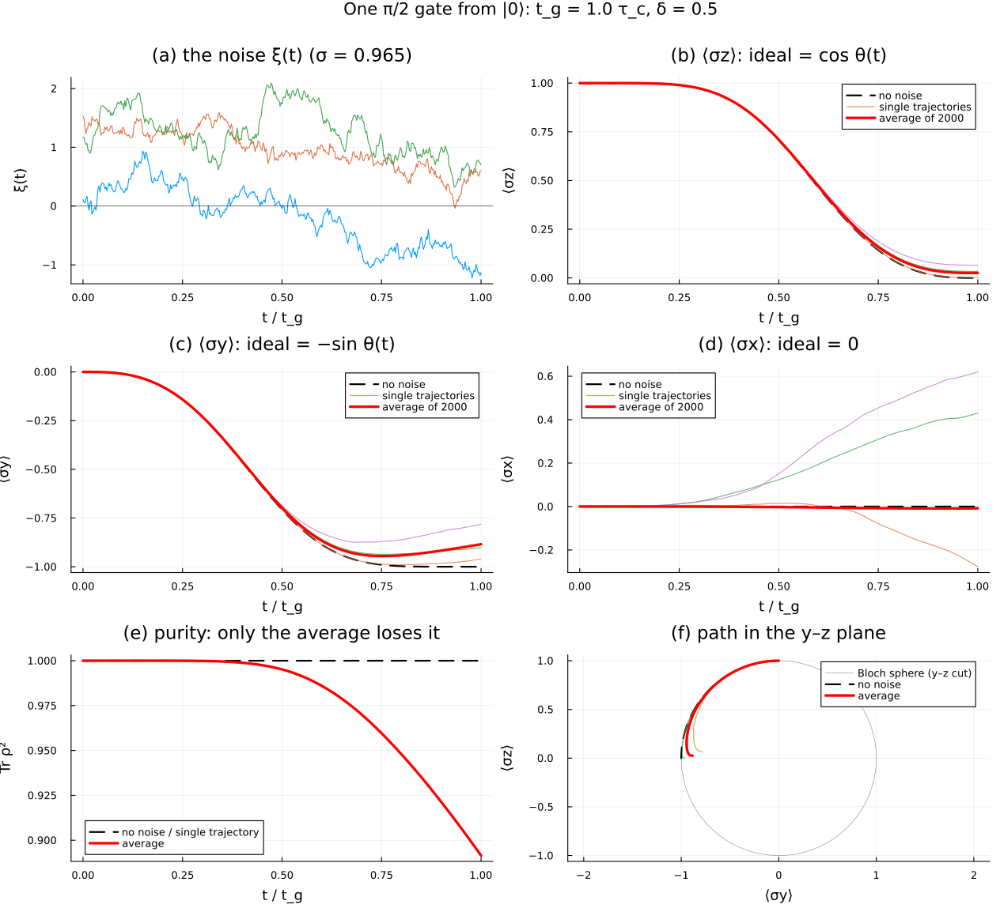

ideal final Bloch vector   = (0.000, -1.000, 0.000)   expected (0, −1, 0)
average final Bloch vector = (-0.008, -0.884, 0.025),  |r| = 0.8849
final purity of the average = 0.8915   (1 = no damage)
gate error ⟨ε⟩ = 0.0735 ± 0.0019


In [59]:
# ── One gate application, watched in time ────────────────────────────────────
tg_w  = 1.0                                   # gate time (units of τ_c = 1)
δ_w   = 0.5                                   # noise strength via Eq. 3.20 (largest δ in Fig. 3.20)…
σ_w   = sigma_for_delta(δ_w, τc, θ, tg_w)     # …or set σ directly to exaggerate it, e.g. σ_w = 3.0
M_w   = 2000                                  # trajectories in the average
nshow = 3                                     # single trajectories to draw
ρ0_w  = cardinal_states().zp                  # start in |0⟩

g_w   = CosineGate(θ, tg_w)
ens_w = generate_ensemble(OUNoiseModel(σ_w, τc), (0.0, tg_w), tg_w / 400, M_w; rng=Xoshiro(SEED + 50))
t_w   = times(ens_w)
x_w   = t_w ./ tg_w

# 1) No noise: ρ(t) = U₀(t) ρ0 U₀(t)†
ideal_w = [bloch_vector(ideal_propagator(g_w, s) * ρ0_w * ideal_propagator(g_w, s)') for s in t_w]
# 2) Single noisy trajectories: each one is solved exactly and stays a pure state
single_ρ = [[apply_channel(S, ρ0_w) for S in propagate_trajectory(g_w, t_w, ens_w[j])] for j in 1:nshow]
single_b = [bloch_vector.(ρs) for ρs in single_ρ]
# 3) The noise average ⟨ρ(t)⟩ over all M_w trajectories: what a master equation describes
r_w   = simulate_gate(g_w, ens_w)
avg_ρ = evolve_state(r_w, ρ0_w).ρ
avg_b = bloch_vector.(avg_ρ)

comp(v, k) = getindex.(v, k)
function bloch_panel(k, name)
    p = plot(x_w, comp(ideal_w, k); lw=2, ls=:dash, color=:black, label="no noise",
             xlabel="t / t_g", ylabel=name, legend=:best)
    for j in 1:nshow
        plot!(p, x_w, comp(single_b[j], k); lw=1, alpha=0.8, label=(j == 1 ? "single trajectories" : false))
    end
    plot!(p, x_w, comp(avg_b, k); lw=3, color=:red, label="average of $M_w")
    return p
end

p_noise = plot(xlabel="t / t_g", ylabel="ξ(t)", title="(a) the noise ξ(t) (σ = $(round(σ_w; digits=3)))")
for j in 1:nshow
    plot!(p_noise, x_w, ens_w[j]; lw=1, label=false)
end
hline!(p_noise, [0.0]; color=:black, lw=0.5, label=false)

p_z = bloch_panel(3, "⟨σz⟩"); title!(p_z, "(b) ⟨σz⟩: ideal = cos θ(t)")
p_y = bloch_panel(2, "⟨σy⟩"); title!(p_y, "(c) ⟨σy⟩: ideal = −sin θ(t)")
p_x = bloch_panel(1, "⟨σx⟩"); title!(p_x, "(d) ⟨σx⟩: ideal = 0")

p_pur = plot(x_w, ones(length(x_w)); lw=2, ls=:dash, color=:black, label="no noise / single trajectory",
             xlabel="t / t_g", ylabel="Tr ρ²", title="(e) purity: only the average loses it")
plot!(p_pur, x_w, purity.(avg_ρ); lw=3, color=:red, label="average")

p_yz = plot(cos.(range(0, 2π; length=200)), sin.(range(0, 2π; length=200)); color=:gray, lw=0.5,
            label="Bloch sphere (y–z cut)", aspect_ratio=:equal, xlabel="⟨σy⟩", ylabel="⟨σz⟩",
            title="(f) path in the y–z plane")
plot!(p_yz, comp(ideal_w, 2), comp(ideal_w, 3); lw=2, ls=:dash, color=:black, label="no noise")
for j in 1:nshow
    plot!(p_yz, comp(single_b[j], 2), comp(single_b[j], 3); lw=1, alpha=0.8, label=false)
end
plot!(p_yz, comp(avg_b, 2), comp(avg_b, 3); lw=3, color=:red, label="average")

fig_w = plot(p_noise, p_z, p_y, p_x, p_pur, p_yz; layout=(3, 2), size=(1150, 1050),
             plot_title="One π/2 gate from |0⟩: t_g = $tg_w τ_c, δ = $δ_w", plot_titlefontsize=13)
display(save!(fig_w, "one_gate_evolution"))

# Numbers to check
e_w = average_error(r_w)
@printf("ideal final Bloch vector   = (%.3f, %.3f, %.3f)   expected (0, −1, 0)\n", ideal_w[end]...)
@printf("average final Bloch vector = (%.3f, %.3f, %.3f),  |r| = %.4f\n", avg_b[end]..., sqrt(sum(abs2, avg_b[end])))
@printf("final purity of the average = %.4f   (1 = no damage)\n", purity(avg_ρ[end]))
@printf("gate error ⟨ε⟩ = %.4f ± %.4f\n", e_w.ε, e_w.se)